# Disneyland reviews: complaint patterns across branches
### BDCC Lab 1

Guest reviews combine descriptions of attractions with comments about queues, prices and service, so a park's overall rating may conceal specific difficulties during a visit. This analysis examines those difficulties by preparing the review data, representing its vocabulary with bag-of-words and TF-IDF, and grouping explicitly mentioned complaints into review-level baskets. We then use Apriori and association rules to compare recurring combinations across branches, while keeping their counts and denominators visible.

The analysis reconciles the group's **BDCC LAB 1.ipynb** draft with the earlier review-analysis workbook. It retains the draft's 5,000-term TF-IDF representation, first-review inspection and sparsity calculation, while removing the repeated vectorizer fit and adding the checks needed for branch comparisons. The set-based transactions, absolute-support convention, Apriori function and single-consequent rules follow the supplied class FIM notebook. The attraction results remain descriptive, and the recommendations concern issues to investigate rather than a validated attraction recommender.

**Reproduction.** Run the notebook from top to bottom. The hosted CSV path is used when available, and an explicitly reported local fallback supports execution beside the CSV. The source data and the two input notebooks are not modified. Section 8 is an optional extension, while the other sections form the main analysis. Interpretations are calculated from the current run rather than copied from earlier outputs.

## 1. Data loading
We load the six supplied columns and preserve review identifiers as strings. The hosted path and Latin-1 encoding follow the group draft, while a file digest and package versions record exactly which input and environment produced the results.

In [1]:
# Run once if the notebook environment does not have these packages.
# %pip install pandas numpy matplotlib scikit-learn vaderSentiment


In [2]:
import hashlib
import html
import importlib.metadata
import json
import platform
import re
from itertools import combinations
from math import ceil
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from sklearn.feature_extraction.text import (
    ENGLISH_STOP_WORDS,
    CountVectorizer,
    TfidfTransformer,
    TfidfVectorizer,
)
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

SEED = 42
DATA_PATH = Path("/mnt/data/public/disneyland-reviews/DisneylandReviews.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path("DisneylandReviews.csv")
    print("Hosted file unavailable; checking the local CSV.")
if not DATA_PATH.exists():
    raise FileNotFoundError(
        "Place the CSV beside this notebook or edit DATA_PATH."
    )

pd.set_option("display.max_colwidth", 100)
plt.rcParams.update(
    {
        "figure.figsize": (10, 4),
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)
raw = pd.read_csv(DATA_PATH, encoding="latin-1", dtype={"Review_ID": "string"})
required = [
    "Review_ID",
    "Rating",
    "Year_Month",
    "Reviewer_Location",
    "Review_Text",
    "Branch",
]
if not set(required).issubset(raw.columns):
    raise ValueError("The input does not contain all six expected columns.")
input_digest = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
print("Input:", DATA_PATH.resolve())
print("Shape:", raw.shape)
display(raw.head(3))
display(raw.dtypes.rename("data_type").to_frame())


Hosted file unavailable; checking the local CSV.


Input: C:\Users\jlgel\Downloads\BDCC-Lab1-\DisneylandReviews.csv
Shape: (42656, 6)


,Review_ID,Rating,Year_Month,Reviewer_Location,Review_Text,Branch
0,670772142,4,2019-4,Australia,If you've ever been to Disneyland anywhere you'll find Disneyland Hong Kong very similar in the ...,Disneyland_HongKong
1,670682799,4,2019-5,Philippines,"Its been a while since d last time we visit HK Disneyland .. Yet, this time we only stay in Tomo...",Disneyland_HongKong
2,670623270,4,2019-4,United Arab Emirates,Thanks God it wasn t too hot or too humid when I was visiting the park otherwise it would be...,Disneyland_HongKong


,data_type
Review_ID,string
Rating,int64
Year_Month,str
Reviewer_Location,str
Review_Text,str
Branch,str


In [3]:
display(Markdown(f"""### Findings and interpretation

The file contains **{len(raw):,} review records and {raw.shape[1]}
columns**, and its identifiers, ratings, dates, locations and text
provide the information needed for branch-level analysis. However,
`Review_ID` identifies a review rather than a person, so we count review
records and do not interpret repeated mentions as independent visitors.
`Reviewer_Location` describes a stated origin, whereas `Branch`
identifies the reviewed park, and the distinction is maintained
throughout the analysis. Latin-1 follows the group draft, although
successful decoding does not establish that all punctuation was
originally encoded correctly."""))


### Findings and interpretation

The file contains **42,656 review records and 6
columns**, and its identifiers, ratings, dates, locations and text
provide the information needed for branch-level analysis. However,
`Review_ID` identifies a review rather than a person, so we count review
records and do not interpret repeated mentions as independent visitors.
`Reviewer_Location` describes a stated origin, whereas `Branch`
identifies the reviewed park, and the distinction is maintained
throughout the analysis. Latin-1 follows the group draft, although
successful decoding does not establish that all punctuation was
originally encoded correctly.

## 2. Cleaning and data-quality checks
We distinguish null values from placeholders, remove only exact duplicate rows, and retain conflicting repeated IDs for inspection. Missing dates or invalid ratings do not remove otherwise usable text. We preserve the original review, repair common broken negation forms in a separate text column, and prepare a lowercase version for vectorization, while sentiment retains capitalization and punctuation.

In [4]:
PLACEHOLDERS = {"", "missing", "unknown", "n/a", "na", "null", "none"}
quality_rows = []
for column in required:
    values = raw[column].astype("string").str.strip()
    missing = values.isna() | values.str.lower().isin(PLACEHOLDERS)
    quality_rows.append(
        {
            "column": column,
            "nulls": raw[column].isna().sum(),
            "missing_including_placeholders": missing.sum(),
            "missing_pct": 100 * missing.mean(),
        }
    )
quality = pd.DataFrame(quality_rows)
exact_duplicates = int(raw.duplicated().sum())
df = raw.drop_duplicates().copy()
df.insert(0, "row_id", df.index)
df = df.reset_index(drop=True)
for column in required:
    if column != "Rating":
        values = df[column].astype("string").str.strip()
        df[column] = values.mask(values.str.lower().isin(PLACEHOLDERS))

numeric_rating = pd.to_numeric(df["Rating"], errors="coerce")
df["rating"] = numeric_rating.where(numeric_rating.isin([1, 2, 3, 4, 5]))
df["review_month"] = pd.to_datetime(
    df["Year_Month"], format="%Y-%m", errors="coerce"
)
for column in ["Branch", "Reviewer_Location"]:
    df[column] = df[column].fillna("Unknown")
df["repeated_id"] = df["Review_ID"].notna() & df["Review_ID"].duplicated(
    keep=False
)


def prepare_text(value):
    """Preserve tone while removing markup and repairing common negations."""
    if pd.isna(value):
        return ""
    text = html.unescape(str(value)).replace("’", "'")
    text = re.sub(r"<[^>]+>|https?://\S+|www\.\S+", " ", text)
    # The CSV often contains forms such as "wasn   t" and "don t".
    text = re.sub(
        r"\b(can|won|isn|aren|wasn|weren|don|doesn|didn|haven|hasn|hadn|"
        r"couldn|wouldn|shouldn|mustn)\s+t\b",
        r"\1't",
        text,
        flags=re.IGNORECASE,
    )
    text = re.sub(
        r"\b(?:dont|doesnt|didnt|isnt|arent|wasnt|werent|havent|hasnt|"
        r"hadnt|couldnt|wouldnt|shouldnt|mustnt)\b",
        lambda match: match.group()[:-1] + "'t",
        text,
        flags=re.IGNORECASE,
    )
    return re.sub(r"\s+", " ", text).strip()


def clean_for_terms(text):
    """Return lowercase tokens while retaining negation words."""
    text = text.lower().replace("can't", "cannot").replace("won't", "will not")
    text = re.sub(r"n't\b", " not", text)
    return re.sub(r"\s+", " ", re.sub(r"[^\w\s]", " ", text)).strip()


df["sentiment_text"] = df["Review_Text"].apply(prepare_text)
df["clean_text"] = df["sentiment_text"].apply(clean_for_terms)
df["word_count"] = df["clean_text"].str.split().str.len()
df["text_eligible"] = df["clean_text"].str.contains(r"\w", regex=True)
text_df = df.loc[df["text_eligible"]].copy().reset_index(drop=True)
if text_df.empty:
    raise ValueError("No usable text remains after cleaning.")
display(quality.round(2))
display(df.loc[df["repeated_id"], ["row_id", "Review_ID", "Branch"]].head(8))
display(text_df[["Review_Text", "clean_text"]].head(2))


,column,nulls,missing_including_placeholders,missing_pct
0,Review_ID,0,0,0.00
1,Rating,0,0,0.00
2,Year_Month,0,2613,6.13
3,Reviewer_Location,0,0,0.00
4,Review_Text,0,0,0.00
5,Branch,0,0,0.00


,row_id,Review_ID,Branch
7858,7858,168489234,Disneyland_HongKong
7867,7867,168489234,Disneyland_HongKong
7940,7940,164830205,Disneyland_HongKong
7949,7950,164830205,Disneyland_HongKong
9168,9172,121615246,Disneyland_HongKong
9169,9173,121615136,Disneyland_HongKong
9178,9182,121615246,Disneyland_HongKong
9179,9183,121615136,Disneyland_HongKong


,Review_Text,clean_text
0,If you've ever been to Disneyland anywhere you'll find Disneyland Hong Kong very similar in the ...,if you ve ever been to disneyland anywhere you ll find disneyland hong kong very similar in the ...
1,"Its been a while since d last time we visit HK Disneyland .. Yet, this time we only stay in Tomo...",its been a while since d last time we visit hk disneyland yet this time we only stay in tomorrow...


In [5]:
display(Markdown(f"""### Findings and interpretation

Removing **{exact_duplicates:,} exact duplicates** leaves **{len(df):,}
records**, of which **{len(text_df):,}** contain usable text. There are
**{df['review_month'].isna().sum():,} unavailable or unparseable dates**
and **{df['rating'].isna().sum():,} unavailable or invalid ratings**, so
these records remain in text analysis but are excluded from calculations
requiring the missing field. A further **{df['repeated_id'].sum():,}
rows share a non-missing ID after exact deduplication**, although their
content differs, and we retain them under separate row keys rather than
deciding arbitrarily which version is correct. Section 7 checks whether
excluding these rows changes the selected rules."""))


### Findings and interpretation

Removing **12 exact duplicates** leaves **42,644
records**, of which **42,644** contain usable text. There are
**2,613 unavailable or unparseable dates**
and **0 unavailable or invalid ratings**, so
these records remain in text analysis but are excluded from calculations
requiring the missing field. A further **16
rows share a non-missing ID after exact deduplication**, although their
content differs, and we retain them under separate row keys rather than
deciding arbitrarily which version is correct. Section 7 checks whether
excluding these rows changes the selected rules.

## 3. Exploratory data analysis
We examine branch sizes, rating distributions, reviewer-location coverage and review dates before comparing text patterns. Counts describe the available sample, and percentages use the relevant branch total, while rating summaries exclude invalid ratings. The location tables describe coverage rather than nationality or visitor populations.

C:\Users\jlgel\AppData\Local\Temp\ipykernel_9028\3450944635.py:22: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(branch_summary.round(2))


,reviews,valid_ratings,mean_rating,median_rating,first_month,last_month,share_pct
Branch,,,,,,,
Disneyland_California,19404,19404,4.41,5.0,2010-04-01,2019-05-01,45.50
Disneyland_HongKong,9611,9611,4.20,4.0,2010-03-01,2019-05-01,22.54
Disneyland_Paris,13629,13629,3.96,4.0,2010-03-01,2019-04-01,31.96


rating,1,2,3,4,5
Branch,,,,,
Disneyland_California,2.6,3.8,8.6,20.5,64.5
Disneyland_HongKong,1.8,3.5,14.2,33.6,47.0
Disneyland_Paris,6.1,7.7,15.3,26.2,44.8


Branch,Disneyland_California,Disneyland_HongKong,Disneyland_Paris
Reviewer_Location,,,
United States,12337,878,1330
United Kingdom,1019,740,7992
Australia,2448,1634,595
Canada,1842,204,188
India,135,1083,293
Philippines,55,991,24
Singapore,93,850,92
New Zealand,527,167,62
Malaysia,30,506,51


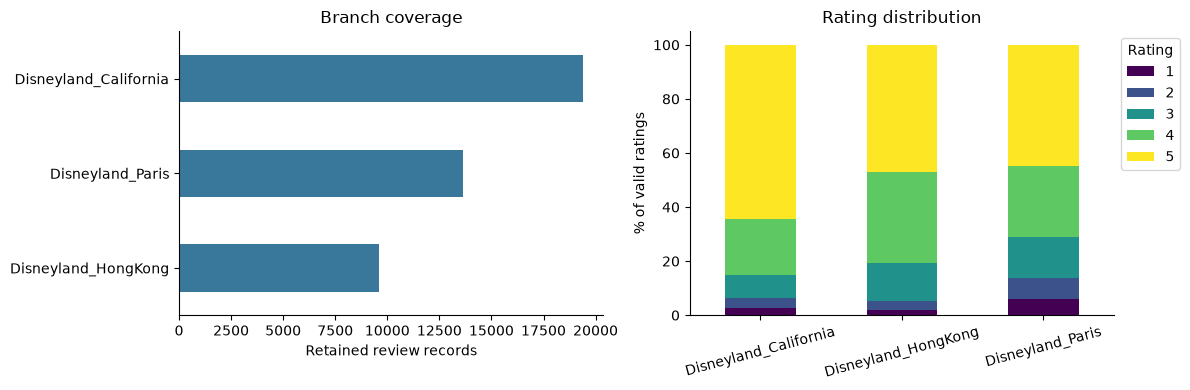

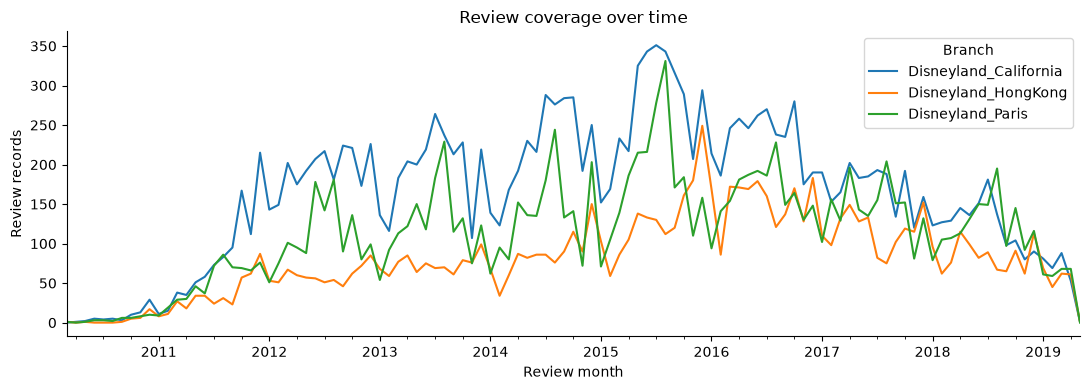

In [6]:
branch_summary = df.groupby("Branch").agg(
    reviews=("row_id", "size"),
    valid_ratings=("rating", "count"),
    mean_rating=("rating", "mean"),
    median_rating=("rating", "median"),
    first_month=("review_month", "min"),
    last_month=("review_month", "max"),
)
branch_summary["share_pct"] = 100 * branch_summary["reviews"] / len(df)
rating_counts = pd.crosstab(df["Branch"], df["rating"]).reindex(
    columns=[1, 2, 3, 4, 5], fill_value=0
)
rating_pct = rating_counts.div(rating_counts.sum(axis=1), axis=0) * 100
location_counts = df["Reviewer_Location"].value_counts()
location_coverage = pd.crosstab(df["Reviewer_Location"], df["Branch"])
location_branch = (
    df.groupby(["Branch", "Reviewer_Location"])
    .agg(reviews=("row_id", "size"), mean_rating=("rating", "mean"))
    .reset_index()
)
location_branch["small_group"] = location_branch["reviews"] < 30
display(branch_summary.round(2))
display(rating_pct.round(1))
display(location_coverage.loc[location_counts.head(10).index])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
branch_summary["reviews"].sort_values().plot.barh(ax=axes[0], color="#39789b")
axes[0].set(
    xlabel="Retained review records", ylabel="", title="Branch coverage"
)
rating_pct.plot.bar(stacked=True, ax=axes[1], rot=15, colormap="viridis")
axes[1].set(
    ylabel="% of valid ratings", xlabel="", title="Rating distribution"
)
axes[1].legend(title="Rating", loc="upper left", bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

monthly = (
    df.dropna(subset=["review_month"])
    .groupby(["review_month", "Branch"])
    .size()
    .unstack(fill_value=0)
)
if not monthly.empty:
    monthly.plot(title="Review coverage over time", figsize=(11, 4))
    plt.ylabel("Review records")
    plt.xlabel("Review month")
    plt.tight_layout()
    plt.show()


In [7]:
display(Markdown(f"""### Findings and interpretation

**{branch_summary['reviews'].idxmax()}** supplies the largest share of
the retained sample at **{branch_summary['share_pct'].max():.1f}%**,
while **{100 * df['rating'].ge(4).sum() / df['rating'].count():.1f}%**
of valid ratings are four or five stars. The generally favorable ratings
therefore provide context for the complaint analysis, because criticism
of one part of a visit need not imply a poor overall experience. The
most common stated reviewer location is **{location_counts.index[0]}**,
which accounts for **{100 * location_counts.iloc[0] / len(df):.1f}%** of
records, and **{location_branch['small_group'].sum():,}** observed
branch-location groups contain fewer than 30 reviews. These imbalances
mean that raw complaint totals and small location-group averages should
not be treated as comparable measures of park quality. The time plot
also describes historical review coverage rather than current operating
conditions."""))


### Findings and interpretation

**Disneyland_California** supplies the largest share of
the retained sample at **45.5%**,
while **79.5%**
of valid ratings are four or five stars. The generally favorable ratings
therefore provide context for the complaint analysis, because criticism
of one part of a visit need not imply a poor overall experience. The
most common stated reviewer location is **United States**,
which accounts for **34.1%** of
records, and **290** observed
branch-location groups contain fewer than 30 reviews. These imbalances
mean that raw complaint totals and small location-group averages should
not be treated as comparable measures of park quality. The time plot
also describes historical review coverage rather than current operating
conditions.

## 4. Word vectorization
We retain the group draft's 5,000-feature limit and TF-IDF inspection, while adding the class notebook's `CountVectorizer` representation. Both matrices use the same vocabulary and row order, and the vocabulary is fitted once across the corpus so branch comparisons remain on the same scale. English stopwords are removed except for negation terms, while a separate bigram table retains stopwords to preserve phrases. We use scikit-learn's smoothed IDF and L2 normalization, so the values are not a literal calculation of the unsmoothed formula shown in the slides.

In [8]:
stop_words = sorted(set(ENGLISH_STOP_WORDS) - {"no", "not", "never", "cannot"})
count_vectorizer = CountVectorizer(
    lowercase=False,
    stop_words=stop_words,
    token_pattern=r"\w+",
    min_df=5,
    max_df=0.95,
    max_features=5000,
)
docs = text_df["clean_text"]
bow = count_vectorizer.fit_transform(docs)
terms = count_vectorizer.get_feature_names_out()
# The fixed vocabulary carries the 5,000-feature cap into TF-IDF.
tfidf_vectorizer = TfidfVectorizer(
    vocabulary=count_vectorizer.vocabulary_,
    lowercase=False,
    stop_words=stop_words,
    token_pattern=r"\w+",
)
tfidf_matrix = tfidf_vectorizer.fit_transform(docs)
term_summary = pd.DataFrame(
    {
        "term": terms,
        "occurrences": np.asarray(bow.sum(axis=0)).ravel(),
        "review_count": np.asarray((bow > 0).sum(axis=0)).ravel(),
        "total_tfidf": np.asarray(tfidf_matrix.sum(axis=0)).ravel(),
        "mean_tfidf": np.asarray(tfidf_matrix.mean(axis=0)).ravel(),
    }
).sort_values("total_tfidf", ascending=False)
sparsity = 100 * (1 - tfidf_matrix.nnz / np.prod(tfidf_matrix.shape))
print("TF-IDF matrix:", tfidf_matrix.shape, "| sparsity:", round(sparsity, 2))
display(term_summary.head(15).round(3))
first = tfidf_matrix.getrow(0)
first_terms = pd.DataFrame({"term": terms[first.indices], "tfidf": first.data})
display(first_terms.sort_values("tfidf", ascending=False).head(10).round(3))

bigram_vectorizer = CountVectorizer(
    ngram_range=(2, 2), min_df=5, max_features=5000
)
bigram_matrix = bigram_vectorizer.fit_transform(docs)
bigram_summary = pd.DataFrame(
    {
        "phrase": bigram_vectorizer.get_feature_names_out(),
        "review_count": np.asarray((bigram_matrix > 0).sum(axis=0)).ravel(),
    }
).sort_values("review_count", ascending=False)
display(bigram_summary.head(15))

branch_term_tables = []
for branch in sorted(text_df["Branch"].unique()):
    mask = text_df["Branch"].eq(branch).to_numpy()
    branch_mean = np.asarray(tfidf_matrix[mask].mean(axis=0)).ravel()
    other_mean = (
        np.asarray(tfidf_matrix[~mask].mean(axis=0)).ravel()
        if (~mask).any()
        else np.full(len(terms), np.nan)
    )
    table = pd.DataFrame(
        {
            "Branch": branch,
            "term": terms,
            "mean_tfidf": branch_mean,
            "difference_from_other_branches": branch_mean - other_mean,
        }
    )
    branch_term_tables.append(table)
branch_terms = pd.concat(branch_term_tables, ignore_index=True)
top_branch_terms = (
    branch_terms.sort_values("difference_from_other_branches", ascending=False)
    .groupby("Branch")
    .head(6)
)
display(top_branch_terms.round(4))


TF-IDF matrix: (42644, 5000) | sparsity: 99.07


,term,occurrences,review_count,total_tfidf,mean_tfidf
2997,not,62322,25540,2377.930,0.056
3163,park,45342,21425,2003.878,0.047
1376,disney,37134,18983,1785.603,0.042
1377,disneyland,33555,19792,1753.810,0.041
3715,rides,35002,20676,1721.017,0.040
4495,time,29895,17741,1560.515,0.037
1239,day,28907,16476,1529.194,0.036
3779,s,25864,13762,1407.518,0.033
2032,great,16630,12075,1277.286,0.030
3278,place,13586,10488,1124.379,0.026


,term,tfidf
6,fairly,0.472
7,familiar,0.269
12,layout,0.266
17,relatively,0.245
15,moved,0.239
5,fabulous,0.215
19,similar,0.214
4,doing,0.192
0,absolutely,0.176
13,ll,0.173


,phrase,review_count
2676,of the,15608
3778,the park,14867
1868,in the,13109
2064,it was,12253
328,and the,10922
1413,for the,10237
1781,if you,9791
4221,to the,9317
3815,the rides,9095
531,at the,8148


,Branch,term,mean_tfidf,difference_from_other_branches
7209,Disneyland_HongKong,hong,0.0389,0.0383
7504,Disneyland_HongKong,kong,0.0389,0.0382
13162,Disneyland_Paris,paris,0.0347,0.0317
7187,Disneyland_HongKong,hk,0.0294,0.0292
13494,Disneyland_Paris,queues,0.0253,0.0186
2621,Disneyland_California,lines,0.0245,0.0165
753,Disneyland_California,california,0.0201,0.0164
9046,Disneyland_HongKong,small,0.0256,0.0161
7916,Disneyland_HongKong,mtr,0.0151,0.0151
13491,Disneyland_Paris,queue,0.0206,0.0145


In [9]:
display(Markdown(f"""### Findings and interpretation

The shared representation contains **{tfidf_matrix.shape[1]:,} terms**
and is **{sparsity:.2f}% sparse**, so retaining it as a sparse matrix
avoids allocating a large table of mostly zeros. The terms with the
largest total TF-IDF weights are
**{', '.join(term_summary.head(5)['term'])}**, while the first review is
particularly represented by
**{', '.join(first_terms.nlargest(3, 'tfidf')['term'])}**. These
summaries answer different questions: the former reflects weight across
the corpus, whereas the latter describes one review. Within a fixed
corpus, total and mean TF-IDF produce the same ordering, but neither is
a sentiment score. The branch contrasts suggest vocabulary to inspect in
context, although prominent words and bigrams do not independently
establish a complaint, and bigrams may cross punctuation boundaries
after cleaning."""))


### Findings and interpretation

The shared representation contains **5,000 terms**
and is **99.07% sparse**, so retaining it as a sparse matrix
avoids allocating a large table of mostly zeros. The terms with the
largest total TF-IDF weights are
**not, park, disney, disneyland, rides**, while the first review is
particularly represented by
**fairly, familiar, layout**. These
summaries answer different questions: the former reflects weight across
the corpus, whereas the latter describes one review. Within a fixed
corpus, total and mean TF-IDF produce the same ordering, but neither is
a sentiment score. The branch contrasts suggest vocabulary to inspect in
context, although prominent words and bigrams do not independently
establish a complaint, and bigrams may cross punctuation boundaries
after cleaning.

## 5. Attraction mentions, complaint categories and contextual sentiment
We match named attractions and services through editable phrase dictionaries, and we label a complaint only when a problem expression is present. Topic and problem words must form a short phrase connected by ordinary linking words, while obvious conditional descriptions are excluded from complaint extraction. A negative sentence that merely mentions a topic is insufficient for the primary baskets. This stricter choice reduces some false positives from the earlier workbook, although it also misses indirect or unfamiliar wording.

VADER scores the sentence or contrast clause containing the evidence, so its label describes the **local context**, not a verified opinion about every aspect in that clause. Negation is checked near the problem cue, and multiple-aspect segments and tentative attraction links remain visible. Price expressions identify descriptions of high cost and do not, by themselves, prove dissatisfaction. The rules are English-oriented, and cross-park comparisons, irony and pronouns still require inspection. Dining and queue/crowd co-mentions are retained as a derived context label rather than a confirmed food-counter problem, and they are excluded from primary FIM because their overlap is created by the labeling rule.

In [10]:
ATTRACTIONS = {
    "Space Mountain": ["space mountain", "hyperspace mountain"],
    "It's a Small World": [
        "it's a small world",
        "its a small world",
        "small world",
    ],
    "Pirates of the Caribbean": ["pirates of the caribbean"],
    "Big Thunder Mountain": ["big thunder mountain", "thunder mountain"],
    "Buzz Lightyear": ["buzz lightyear"],
    "Haunted Mansion": ["haunted mansion"],
    "Phantom Manor": ["phantom manor"],
    "Jungle Cruise": ["jungle cruise", "jungle river cruise"],
    "Iron Man Experience": ["iron man experience", "ironman experience"],
    "Mystic Manor": ["mystic manor"],
    "Ratatouille": ["ratatouille"],
    "Dumbo": ["dumbo"],
    "Railroad": ["disneyland railroad", "disney railroad"],
}
SERVICES = {
    "Staff / customer service": [
        "staff",
        "cast member",
        "cast members",
        "customer service",
        "employees",
    ],
    "Food / dining": [
        "food",
        "restaurant",
        "restaurants",
        "food counter",
        "food counters",
        "meal",
        "meals",
        "dining",
    ],
    "Tickets / admission": ["ticket", "tickets", "admission", "entry fee"],
    "Queue / fast pass": [
        "queue",
        "queues",
        "waiting time",
        "wait time",
        "fastpass",
        "fast pass",
    ],
    "Cleanliness / toilets": [
        "toilet",
        "toilets",
        "restroom",
        "restrooms",
        "bathroom",
        "bathrooms",
        "cleanliness",
    ],
    "Shows / entertainment": ["parade", "parades", "fireworks", "shows"],
    "Transport / parking": ["parking", "shuttle", "shuttles", "transport"],
}


In [11]:
def compile_aliases(dictionary):
    """Compile complete-word aliases for each attraction or service label."""
    patterns = {}
    for label, aliases in dictionary.items():
        alternatives = [
            re.escape(alias)
            for alias in sorted(aliases, key=len, reverse=True)
        ]
        patterns[label] = re.compile(
            r"\b(?:" + "|".join(alternatives) + r")\b", re.I
        )
    return patterns


def find_labels(text, patterns):
    """Return the labels whose aliases occur in a text segment."""
    return [
        label for label, pattern in patterns.items() if pattern.search(text)
    ]


def nearby_patterns(topic, cue):
    """Connect topic and cue through at most four ordinary linking words."""
    links = (
        r"is|are|was|were|be|been|being|very|quite|really|so|too|"
        r"all|the|a|bit|generally|extremely|absolutely|which|that|"
        r"either|still|often|sometimes|not|never|only|"
        r"at|in|of|quality|attitude"
    )
    # Restrict the gap so it cannot jump across another aspect or a comma.
    gap = r"(?:\s+(?:" + links + r")){0,4}\s+"
    first = r"\b(?:" + topic + r")\b" + gap + r"(?P<cue>" + cue + r")\b"
    second = r"\b(?P<cue>" + cue + r")\b" + gap + r"(?:" + topic + r")\b"
    return [re.compile(first, re.I), re.compile(second, re.I)]


attraction_patterns = compile_aliases(ATTRACTIONS)
service_patterns = compile_aliases(SERVICES)
ride_topics = r"rides?|attractions?|roller\s*coasters?|" + "|".join(
    re.escape(alias) for aliases in ATTRACTIONS.values() for alias in aliases
)
# Each category requires an explicit cue, rather than general negativity.
COMPLAINT_RULES = {
    "Long queues": nearby_patterns(
        r"queues?|lines?|waits?|waiting", r"long|lengthy|slow|huge|massive"
    ),
    "Closures / breakdowns": nearby_patterns(
        ride_topics,
        r"closed|broken\s+down|broke\s+down|not\s+working|"
        r"out\s+of\s+service|under\s+maintenance|shut\s+down",
    ),
    "Poor staff service": nearby_patterns(
        r"staff|cast\s+members?|employees?|service",
        r"rude|unhelpful|unfriendly|impolite|poor|terrible|awful",
    ),
    "High prices / poor value": [
        re.compile(
            r"\b(?P<cue>expensive|overpriced|pricey|poor\s+value|"
            r"waste\s+of\s+money|not\s+worth\s+(?:the\s+)?"
            r"(?:money|price|cost))\b",
            re.I,
        )
    ],
    "Food quality / dining": nearby_patterns(
        r"food|meals?|restaurants?|lunch|dinner|burgers?|pizza",
        r"cold|stale|undercooked|poor|bad|terrible|awful|disgusting",
    ),
    "Crowding": [
        re.compile(
            r"\b(?P<cue>overcrowded|too\s+crowded|very\s+crowded|"
            r"extremely\s+crowded|uncomfortably\s+crowded)\b",
            re.I,
        )
    ],
    "Cleanliness": nearby_patterns(
        r"park|toilets?|restrooms?|bathrooms?|tables?|floors?|restaurant",
        r"dirty|filthy|unclean|disgusting",
    ),
}
PRIMARY_CATEGORIES = sorted(COMPLAINT_RULES)


def negated_cue(text, start):
    """Check a short negation window without treating 'not only' as denial."""
    prefix = text[:start].lower()
    prefix = re.split(r"[.!?;:]|\b(?:but|however|although|yet)\b", prefix)[-1]
    if re.search(r"\bnot\s+that\b", prefix):
        return True
    denial = re.search(
        r"\b(?:don't|doesn't|didn't|do\s+not|does\s+not)\s+have\s+to\b|"
        r"\bno\s+need\s+to\b",
        prefix[-100:],
    )
    if denial:
        return True
    prefix = re.sub(r"\bnot\s+only\b", "", prefix)
    words = re.findall(r"[\w']+", prefix)[-4:]
    negatives = {
        "no",
        "not",
        "never",
        "without",
        "hardly",
        "cannot",
        "wasn't",
        "weren't",
        "isn't",
        "aren't",
        "don't",
        "didn't",
    }
    return any(word in negatives for word in words)


def detect_complaints(segment):
    """Return one explicit evidence match per complaint category."""
    hypothetical = re.search(
        r"^\s*(?:if|unless)\b|\b(?:can|could|would)\s+(?:be|get|see)\b|"
        r"\bwould\s+(?:probably\s+)?say\b",
        segment,
        flags=re.I,
    )
    if hypothetical:
        return []
    hits = []
    for category, patterns in COMPLAINT_RULES.items():
        for pattern in patterns:
            accepted = None
            for match in pattern.finditer(segment):
                if negated_cue(segment, match.start("cue")):
                    continue
                # Scheduled closing times are not sufficient closure evidence.
                cue_end = match.end("cue")
                tail = segment[cue_end:]
                if category == "Closures / breakdowns" and re.match(
                    r"\s+at\s+\d", tail, flags=re.I
                ):
                    continue
                accepted = match
                break
            if accepted:
                hits.append(
                    {
                        "category": category,
                        "evidence": accepted.group(),
                        "cue": accepted.group("cue"),
                        "primary": True,
                    }
                )
                break
    dining = service_patterns["Food / dining"].search(segment)
    if dining and any(
        hit["category"] in {"Long queues", "Crowding"} for hit in hits
    ):
        hits.append(
            {
                "category": "Dining with queue/crowd mentions",
                "evidence": segment,
                "cue": "dining with queue/crowding cue",
                "primary": False,
            }
        )
    return hits


def split_segments(text):
    """Split sentences and contrast clauses while preserving punctuation."""
    pieces = re.split(
        r"(?<=[.!?;])\s+|(?<=[.!?;])(?=[A-Z])|"
        r"\b(?:but|however|although|yet)\b",
        text,
        flags=re.I,
    )
    return [piece.strip(" ,;") for piece in pieces if piece.strip(" ,;")]


def sentiment_label(score):
    """Apply the usual VADER compound thresholds to local context."""
    if score >= 0.05:
        return "positive"
    if score <= -0.05:
        return "negative"
    return "neutral"


In [12]:
analyzer = SentimentIntensityAnalyzer()
mention_rows = []
complaint_rows = []
for position, row in enumerate(text_df.itertuples(index=False), start=1):
    for segment_id, segment in enumerate(split_segments(row.sentiment_text)):
        attractions = find_labels(segment, attraction_patterns)
        services = find_labels(segment, service_patterns)
        hits = detect_complaints(segment)
        if not attractions and not services and not hits:
            continue
        score = analyzer.polarity_scores(segment)["compound"]
        common = {
            "row_id": row.row_id,
            "Review_ID": row.Review_ID,
            "Branch": row.Branch,
            "segment_id": segment_id,
            "segment": segment,
            "compound": score,
            "context_sentiment": sentiment_label(score),
        }
        for kind, labels in [
            ("attraction", attractions),
            ("service", services),
        ]:
            for aspect in labels:
                mention_rows.append(
                    {
                        **common,
                        "aspect_type": kind,
                        "aspect": aspect,
                        "multiple_aspects": len(attractions) + len(services)
                        > 1,
                    }
                )
        for hit in hits:
            complaint_rows.append(
                {
                    **common,
                    **hit,
                    "candidate_attraction": (
                        attractions[0] if len(attractions) == 1 else None
                    ),
                    "link_status": (
                        "candidate_same_segment"
                        if len(attractions) == 1
                        else (
                            "ambiguous" if len(attractions) > 1 else "unlinked"
                        )
                    ),
                }
            )
    if position % 10000 == 0:
        print(f"Processed {position:,} reviews")

common_cols = [
    "row_id",
    "Review_ID",
    "Branch",
    "segment_id",
    "segment",
    "compound",
    "context_sentiment",
]
mentions = pd.DataFrame(
    mention_rows,
    columns=common_cols + ["aspect_type", "aspect", "multiple_aspects"],
)
complaints = pd.DataFrame(
    complaint_rows,
    columns=common_cols
    + [
        "category",
        "evidence",
        "cue",
        "primary",
        "candidate_attraction",
        "link_status",
    ],
)
primary_complaints = complaints.loc[complaints["primary"].eq(True)].copy()

# Average within a review before aggregating an aspect across reviews.
aspect_reviews = (
    mentions.groupby(["row_id", "Branch", "aspect_type", "aspect"])
    .agg(
        mean_context_score=("compound", "mean"),
        positive_context=("compound", lambda values: values.ge(0.05).any()),
        negative_context=("compound", lambda values: values.le(-0.05).any()),
    )
    .reset_index()
)
aspect_reviews["mixed_context"] = (
    aspect_reviews["positive_context"] & aspect_reviews["negative_context"]
)
aspect_summary = (
    aspect_reviews.groupby(["Branch", "aspect_type", "aspect"])
    .agg(
        reviews=("row_id", "nunique"),
        mean_context_score=("mean_context_score", "mean"),
        mixed_context_reviews=("mixed_context", "sum"),
    )
    .reset_index()
    .sort_values("reviews", ascending=False)
)
denominators = text_df.groupby("Branch").size().rename("text_reviews")
all_pairs = pd.MultiIndex.from_product(
    [denominators.index, PRIMARY_CATEGORIES], names=["Branch", "category"]
)
complaint_summary = (
    primary_complaints.groupby(["Branch", "category"])["row_id"]
    .nunique()
    .reindex(all_pairs, fill_value=0)
    .rename("reviews")
    .reset_index()
    .merge(denominators, on="Branch")
)
complaint_summary["review_pct"] = (
    100 * complaint_summary["reviews"] / complaint_summary["text_reviews"]
)
display(aspect_summary.head(12).round(3))
display(
    complaint_summary.pivot(
        index="category", columns="Branch", values="review_pct"
    ).round(2)
)
display(
    complaints[
        ["row_id", "category", "evidence", "context_sentiment", "link_status"]
    ].head(8)
)

# Save balanced examples for qualitative review without claiming accuracy.
audit_parts = []
for _, group in primary_complaints.groupby(["Branch", "category"]):
    audit_parts.append(group.sample(n=min(2, len(group)), random_state=SEED))
extraction_audit = (
    pd.concat(audit_parts, ignore_index=True)
    if audit_parts
    else primary_complaints.copy()
)
extraction_audit["reviewer_judgment"] = ""
extraction_audit["notes"] = ""
unmatched = text_df.loc[~text_df["row_id"].isin(primary_complaints["row_id"])]
unmatched_audit = unmatched.sample(
    n=min(30, len(unmatched)), random_state=SEED
)[["row_id", "Branch", "Review_Text"]].copy()
unmatched_audit["missed_categories"] = ""
attraction_review_count = mentions.loc[
    mentions["aspect_type"].eq("attraction"), "row_id"
].nunique()


Processed 10,000 reviews


Processed 20,000 reviews


Processed 30,000 reviews


Processed 40,000 reviews


,Branch,aspect_type,aspect,reviews,mean_context_score,mixed_context_reviews
50,Disneyland_Paris,service,Food / dining,5678,0.118,652
51,Disneyland_Paris,service,Queue / fast pass,5647,0.127,815
52,Disneyland_Paris,service,Shows / entertainment,5030,0.388,275
13,Disneyland_California,service,Shows / entertainment,4568,0.337,229
11,Disneyland_California,service,Food / dining,4525,0.256,225
12,Disneyland_California,service,Queue / fast pass,4139,0.214,231
33,Disneyland_HongKong,service,Shows / entertainment,3838,0.342,207
53,Disneyland_Paris,service,Staff / customer service,3728,0.266,376
14,Disneyland_California,service,Staff / customer service,3212,0.417,200
31,Disneyland_HongKong,service,Food / dining,2928,0.175,135


Branch,Disneyland_California,Disneyland_HongKong,Disneyland_Paris
category,,,
Cleanliness,0.20,0.06,1.00
Closures / breakdowns,4.75,1.43,10.33
Crowding,2.88,1.51,1.53
Food quality / dining,0.38,0.43,1.91
High prices / poor value,11.61,12.88,23.66
Long queues,9.20,6.75,11.17
Poor staff service,0.45,0.31,1.75


,row_id,category,evidence,context_sentiment,link_status
0,5,High prices / poor value,expensive,positive,unlinked
1,5,High prices / poor value,expensive,neutral,unlinked
2,8,Closures / breakdowns,rides were not working,positive,unlinked
3,8,Poor staff service,terrible staff,positive,unlinked
4,15,High prices / poor value,expensive,positive,unlinked
5,17,High prices / poor value,expensive,neutral,unlinked
6,23,High prices / poor value,expensive,neutral,unlinked
7,26,High prices / poor value,expensive,positive,unlinked


In [13]:
display(Markdown(f"""### Findings and interpretation

The explicit rules identify at least one primary complaint category in
**{primary_complaints['row_id'].nunique():,} of {len(text_df):,} usable
reviews
({100 * primary_complaints['row_id'].nunique() / len(text_df):.1f}%)**,
while the attraction dictionary identifies named attractions in
**{attraction_review_count:,} reviews**. Because
**{100 * mentions['multiple_aspects'].mean():.1f}%** of mention records
share a segment with another recognized aspect, the sentiment scores
should be read as contextual evidence rather than isolated attraction
ratings. An explicit problem cue can also occur in a positive segment
when a reviewer describes an inconvenience but remains satisfied. The
exported matched and unmatched samples support qualitative checking, but
they do not constitute a human-labeled benchmark, so no precision or
recall claim is made for the extraction. Consequently, the following
mining results concern detected expressions rather than the prevalence
of every true complaint.

During reconciliation, a qualitative check of sampled evidence exposed
denials, conditional descriptions and phrases that linked a topic to
criticism of something else. Those cases informed the revised rules and
regression checks, so this was a development check rather than an
independent validation sample. General descriptions and accepted high
prices can still produce candidate labels, while indirect complaints can
be missed, which is why the evidence text remains part of the exported
results."""))


### Findings and interpretation

The explicit rules identify at least one primary complaint category in
**12,193 of 42,644 usable
reviews
(28.6%)**,
while the attraction dictionary identifies named attractions in
**8,107 reviews**. Because
**21.1%** of mention records
share a segment with another recognized aspect, the sentiment scores
should be read as contextual evidence rather than isolated attraction
ratings. An explicit problem cue can also occur in a positive segment
when a reviewer describes an inconvenience but remains satisfied. The
exported matched and unmatched samples support qualitative checking, but
they do not constitute a human-labeled benchmark, so no precision or
recall claim is made for the extraction. Consequently, the following
mining results concern detected expressions rather than the prevalence
of every true complaint.

During reconciliation, a qualitative check of sampled evidence exposed
denials, conditional descriptions and phrases that linked a topic to
criticism of something else. Those cases informed the revised rules and
regression checks, so this was a development check rather than an
independent validation sample. General descriptions and accepted high
prices can still produce candidate labels, while indirect complaints can
be missed, which is why the evidence text remains part of the exported
results.

## 6. Frequent itemsets and association rules
Each usable review becomes a set of primary complaint categories, so repeated expressions count once and empty or singleton baskets remain in the denominator. This differs deliberately from the retail example's removal of small baskets, because our question concerns co-mentions among all usable reviews. We keep branch identities separate and exclude unknown branches from cross-branch interpretation.

Following the class convention, `support` in the mining functions is an **absolute count**, while `relative_support` in the tables is that count divided by the branch total. Confidence is `support(A ∪ B) / support(A)`, and lift divides confidence by the baseline prevalence of B. We use all frequent itemsets, since rules require subset supports, and generate single-category consequents as in the reference. The exploratory thresholds are 1% relative support, at least 30 reviews, 30% confidence and 1.2 lift; none is a statistical significance threshold.

In [14]:
MIN_SUPPORT = 0.01
MIN_COUNT = 30
MIN_CONFIDENCE = 0.30
MIN_LIFT = 1.20
category_lists = primary_complaints.groupby("row_id")["category"].agg(
    lambda values: sorted(set(values))
)
baskets_df = text_df[
    [
        "row_id",
        "Review_ID",
        "Branch",
        "Reviewer_Location",
        "rating",
        "word_count",
        "repeated_id",
    ]
].copy()
baskets_df["basket"] = baskets_df["row_id"].apply(
    lambda row_id: set(category_lists.get(row_id, []))
)
baskets_df["basket_size"] = baskets_df["basket"].str.len()
basket_coverage = baskets_df.groupby("Branch").agg(
    reviews=("row_id", "size"),
    empty=("basket_size", lambda sizes: sizes.eq(0).sum()),
    singleton=("basket_size", lambda sizes: sizes.eq(1).sum()),
    multiple=("basket_size", lambda sizes: sizes.ge(2).sum()),
)
basket_coverage["min_count"] = basket_coverage["reviews"].apply(
    lambda total: max(MIN_COUNT, ceil(MIN_SUPPORT * total))
)
display(basket_coverage)


def support_count(db, itemset):
    """Count transactions that contain every item in an itemset."""
    wanted = set(itemset)
    return sum(wanted.issubset(transaction) for transaction in db)


def apriori(db, minsup):
    """Return all frequent itemsets with absolute support, in class order."""
    if minsup < 1:
        raise ValueError("Minimum absolute support must be positive.")
    items = sorted({item for transaction in db for item in transaction})
    candidates = [(item,) for item in items]
    frequent = []
    size = 1
    while candidates:
        level = []
        for itemset in candidates:
            count = support_count(db, itemset)
            if count >= minsup:
                level.append((itemset, count))
        frequent.extend(level)
        if not level:
            break
        previous = {itemset for itemset, count in level}
        next_candidates = set()
        for first, second in combinations(sorted(previous), 2):
            if first[:-1] != second[:-1]:
                continue
            joined = tuple(sorted(set(first) | set(second)))
            if len(joined) == size + 1 and all(
                subset in previous for subset in combinations(joined, size)
            ):
                next_candidates.add(joined)
        candidates = sorted(next_candidates)
        size += 1
    return sorted(
        frequent, key=lambda result: (-result[1], -len(result[0]), result[0])
    )


def assoc(fi, minconf, db_size):
    """Return single-consequent rules with class-style counts and ordering."""
    if not 0 <= minconf <= 1:
        raise ValueError("Minimum confidence must be between zero and one.")
    if db_size <= 0:
        return []
    counts = dict(fi)
    rules = []
    for itemset, count in fi:
        if len(itemset) < 2:
            continue
        for consequent in itemset:
            antecedent = tuple(item for item in itemset if item != consequent)
            confidence = count / counts[antecedent]
            if confidence >= minconf:
                rules.append(
                    {
                        "antecedent": antecedent,
                        "consequent": consequent,
                        "support": count,
                        "confidence": confidence,
                        "lift": confidence / (counts[(consequent,)] / db_size),
                    }
                )
    return sorted(
        rules,
        key=lambda rule: (
            -rule["lift"],
            -rule["confidence"],
            -rule["support"],
            rule["consequent"],
            rule["antecedent"],
        ),
    )


,reviews,empty,singleton,multiple,min_count
Branch,,,,,
Disneyland_California,19404,14639,3928,837,195
Disneyland_HongKong,9611,7608,1778,225,97
Disneyland_Paris,13629,8204,4094,1331,137


In [15]:
branch_baskets = {
    branch: group["basket"].tolist()
    for branch, group in baskets_df.groupby("Branch")
    if branch != "Unknown"
}
itemset_rows = []
rule_rows = []
for branch, db in branch_baskets.items():
    minimum = max(MIN_COUNT, ceil(MIN_SUPPORT * len(db)))
    frequent = apriori(db, minimum)
    for itemset, count in frequent:
        itemset_rows.append(
            {
                "Branch": branch,
                "itemset": itemset,
                "size": len(itemset),
                "support": count,
                "relative_support": count / len(db),
                "total_reviews": len(db),
            }
        )
    for rule in assoc(frequent, MIN_CONFIDENCE, len(db)):
        if rule["lift"] >= MIN_LIFT:
            rule_rows.append(
                {
                    "Branch": branch,
                    **rule,
                    "relative_support": rule["support"] / len(db),
                    "total_reviews": len(db),
                }
            )
frequent_itemsets = pd.DataFrame(
    itemset_rows,
    columns=[
        "Branch",
        "itemset",
        "size",
        "support",
        "relative_support",
        "total_reviews",
    ],
)
selected_rules = pd.DataFrame(
    rule_rows,
    columns=[
        "Branch",
        "antecedent",
        "consequent",
        "support",
        "confidence",
        "lift",
        "relative_support",
        "total_reviews",
    ],
)
selected_rules["rule"] = [
    " + ".join(a) + " → " + b
    for a, b in zip(selected_rules["antecedent"], selected_rules["consequent"])
]
for branch in branch_baskets:
    print(branch)
    display(
        frequent_itemsets.loc[
            frequent_itemsets["Branch"].eq(branch)
            & frequent_itemsets["size"].ge(2)
        ]
        .head(8)
        .round(3)
    )
    display(
        selected_rules.loc[
            selected_rules["Branch"].eq(branch),
            ["rule", "support", "relative_support", "confidence", "lift"],
        ]
        .head(8)
        .round(3)
    )


Disneyland_California


,Branch,itemset,size,support,relative_support,total_reviews
4,Disneyland_California,"(High prices / poor value, Long queues)",2,365,0.019,19404


,rule,support,relative_support,confidence,lift


Disneyland_HongKong


,Branch,itemset,size,support,relative_support,total_reviews
8,Disneyland_HongKong,"(High prices / poor value, Long queues)",2,138,0.014,9611


,rule,support,relative_support,confidence,lift


Disneyland_Paris


,Branch,itemset,size,support,relative_support,total_reviews
13,Disneyland_Paris,"(High prices / poor value, Long queues)",2,529,0.039,13629
14,Disneyland_Paris,"(Closures / breakdowns, High prices / poor value)",2,418,0.031,13629
17,Disneyland_Paris,"(Closures / breakdowns, Long queues)",2,212,0.016,13629


,rule,support,relative_support,confidence,lift
0,Long queues → High prices / poor value,529,0.039,0.347,1.468


In [16]:
display(Markdown(f"""### Findings and interpretation

Across the branches, the selected thresholds yield
**{len(frequent_itemsets):,} frequent itemsets**, including single
categories, and the number of association rules meeting all cutoffs is
**{len(selected_rules):,}**. There are
**{baskets_df['basket_size'].eq(0).sum():,} empty baskets**, which
remain in the denominator because the absence of a detected expression
is still part of the observed sample. A rule therefore describes how
categories co-occur within reviews, and its confidence is conditional on
the antecedent being detected rather than a probability that a visitor
will experience the consequent. Higher lift suggests stronger departure
from an independence baseline, but a high-lift rule can still be
uncommon, so counts and relative support remain essential when choosing
what to inspect."""))


### Findings and interpretation

Across the branches, the selected thresholds yield
**19 frequent itemsets**, including single
categories, and the number of association rules meeting all cutoffs is
**1**. There are
**30,451 empty baskets**, which
remain in the denominator because the absence of a detected expression
is still part of the observed sample. A rule therefore describes how
categories co-occur within reviews, and its confidence is conditional on
the antecedent being detected rather than a probability that a visitor
will experience the consequent. Higher lift suggests stronger departure
from an independence baseline, but a high-lift rule can still be
uncommon, so counts and relative support remain essential when choosing
what to inspect.

## 7. Branch comparisons and robustness
We recount every selected itemset and rule in every branch, including branches where the pattern falls below the mining threshold. Thus, zero support means no observed matches rather than “not selected,” and confidence is missing when its antecedent is absent. We then vary the support threshold and repeat mining after excluding all conflicting repeated IDs, while retaining the same treatment of empty baskets.

,Branch,antecedent,consequent,support,antecedent_count,consequent_count,relative_support,confidence,lift,passes_thresholds
0,Disneyland_California,"(Long queues,)",High prices / poor value,365,1785,2253,0.019,0.204,1.761,False
1,Disneyland_HongKong,"(Long queues,)",High prices / poor value,138,649,1238,0.014,0.213,1.651,False
2,Disneyland_Paris,"(Long queues,)",High prices / poor value,529,1523,3225,0.039,0.347,1.468,True


Branch,Disneyland_California,Disneyland_HongKong,Disneyland_Paris
pattern,,,
High prices / poor value + Long queues,1.88,1.44,3.88
Closures / breakdowns + High prices / poor value,0.75,0.24,3.07
Closures / breakdowns + Long queues,0.76,0.04,1.56


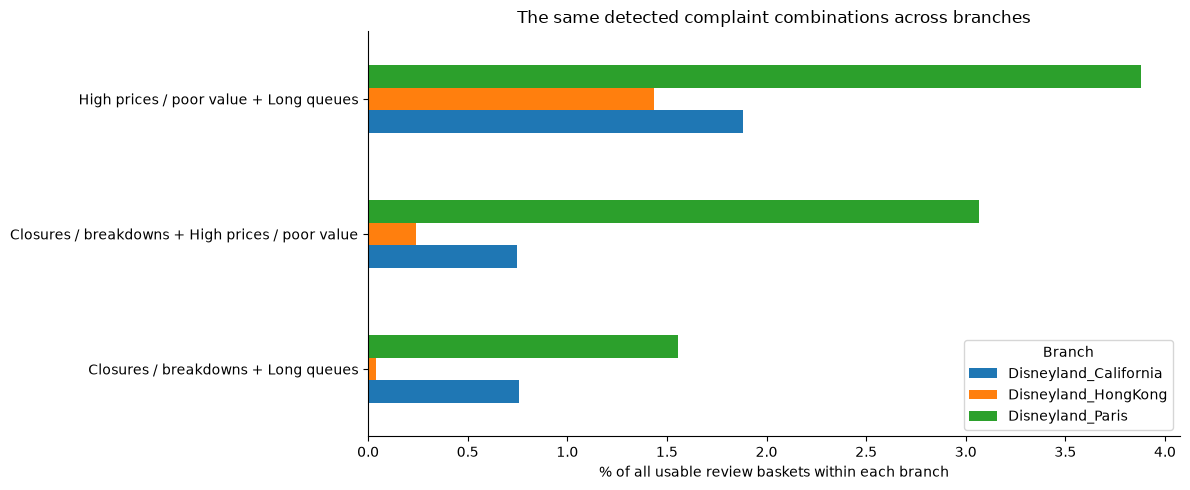

,Branch,min_relative_support,multi_itemsets,selected_rules
0,Disneyland_California,0.005,5,0
1,Disneyland_California,0.010,1,0
2,Disneyland_California,0.020,0,0
3,Disneyland_HongKong,0.005,1,0
4,Disneyland_HongKong,0.010,1,0
5,Disneyland_HongKong,0.020,0,0
6,Disneyland_Paris,0.005,7,5
7,Disneyland_Paris,0.010,3,1
8,Disneyland_Paris,0.020,2,1


,Branch,original_rules,rules_without_repeated_ids,removed_rules,new_rules
0,Disneyland_California,0,0,0,0
1,Disneyland_HongKong,0,0,0,0
2,Disneyland_Paris,1,1,0,0


In [17]:
shared_sets = sorted(
    set(frequent_itemsets.loc[frequent_itemsets["size"].ge(2), "itemset"])
)
comparison_rows = []
for itemset in shared_sets:
    for branch, db in branch_baskets.items():
        count = support_count(db, itemset)
        comparison_rows.append(
            {
                "Branch": branch,
                "itemset": itemset,
                "pattern": " + ".join(itemset),
                "support": count,
                "relative_support": count / len(db),
                "total_reviews": len(db),
            }
        )
itemset_comparison = pd.DataFrame(
    comparison_rows,
    columns=[
        "Branch",
        "itemset",
        "pattern",
        "support",
        "relative_support",
        "total_reviews",
    ],
)

rule_keys = sorted(
    set(zip(selected_rules["antecedent"], selected_rules["consequent"]))
)
rule_comparison_rows = []
for antecedent, consequent in rule_keys:
    for branch, db in branch_baskets.items():
        joint = support_count(db, set(antecedent) | {consequent})
        a_count = support_count(db, antecedent)
        b_count = support_count(db, {consequent})
        confidence = joint / a_count if a_count else np.nan
        lift = (
            confidence / (b_count / len(db)) if a_count and b_count else np.nan
        )
        rule_comparison_rows.append(
            {
                "Branch": branch,
                "antecedent": antecedent,
                "consequent": consequent,
                "support": joint,
                "antecedent_count": a_count,
                "consequent_count": b_count,
                "relative_support": joint / len(db),
                "confidence": confidence,
                "lift": lift,
                "passes_thresholds": joint
                >= max(MIN_COUNT, ceil(MIN_SUPPORT * len(db)))
                and confidence >= MIN_CONFIDENCE
                and lift >= MIN_LIFT,
            }
        )
rule_comparison = pd.DataFrame(
    rule_comparison_rows,
    columns=[
        "Branch",
        "antecedent",
        "consequent",
        "support",
        "antecedent_count",
        "consequent_count",
        "relative_support",
        "confidence",
        "lift",
        "passes_thresholds",
    ],
)
display(rule_comparison.head(15).round(3))
if not itemset_comparison.empty:
    support_pivot = 100 * itemset_comparison.pivot(
        index="pattern", columns="Branch", values="relative_support"
    )
    top_patterns = support_pivot.max(axis=1).nlargest(6).index
    display(support_pivot.loc[top_patterns].round(2))
    support_pivot.loc[top_patterns].iloc[::-1].plot.barh(figsize=(12, 5))
    plt.xlabel("% of all usable review baskets within each branch")
    plt.ylabel("")
    plt.title("The same detected complaint combinations across branches")
    plt.tight_layout()
    plt.show()

sensitivity_rows = []
duplicate_sensitivity_rows = []
for branch, db in branch_baskets.items():
    for threshold in [0.005, 0.01, 0.02]:
        frequent = apriori(db, max(MIN_COUNT, ceil(threshold * len(db))))
        rules = assoc(frequent, MIN_CONFIDENCE, len(db))
        sensitivity_rows.append(
            {
                "Branch": branch,
                "min_relative_support": threshold,
                "multi_itemsets": sum(
                    len(items) >= 2 for items, count in frequent
                ),
                "selected_rules": sum(
                    rule["lift"] >= MIN_LIFT for rule in rules
                ),
            }
        )
    clean_db = baskets_df.loc[
        baskets_df["Branch"].eq(branch) & ~baskets_df["repeated_id"], "basket"
    ].tolist()
    clean_fi = apriori(
        clean_db, max(MIN_COUNT, ceil(MIN_SUPPORT * len(clean_db)))
    )
    clean_keys = {
        (rule["antecedent"], rule["consequent"])
        for rule in assoc(clean_fi, MIN_CONFIDENCE, len(clean_db))
        if rule["lift"] >= MIN_LIFT
    }
    original = selected_rules.loc[selected_rules["Branch"].eq(branch)]
    original_keys = set(zip(original["antecedent"], original["consequent"]))
    duplicate_sensitivity_rows.append(
        {
            "Branch": branch,
            "original_rules": len(original_keys),
            "rules_without_repeated_ids": len(clean_keys),
            "removed_rules": len(original_keys - clean_keys),
            "new_rules": len(clean_keys - original_keys),
        }
    )
sensitivity = pd.DataFrame(sensitivity_rows)
duplicate_sensitivity = pd.DataFrame(duplicate_sensitivity_rows)
display(sensitivity)
display(duplicate_sensitivity)


In [18]:
if itemset_comparison.empty:
    branch_finding = (
        "No multi-category itemset passed the primary support cutoff, so the"
        " current analysis does not support a branch-level comparison of"
        " frequent combinations."
    )
else:
    leading = itemset_comparison.sort_values(
        "relative_support", ascending=False
    ).iloc[0]
    same = itemset_comparison.loc[
        itemset_comparison["itemset"].apply(
            lambda item: item == leading["itemset"]
        )
    ]
    percentages = "; ".join(
        f"{row.Branch}: {100 * row.relative_support:.2f}%"
        for row in same.itertuples()
    )
    branch_finding = (
        "The largest observed branch-level support among the compared"
        f" combinations is for **{leading['pattern']}**. For that same"
        f" combination, the rates are **{percentages}**, with each denominator"
        " including all usable reviews in that branch."
    )
changed_rules = int(
    duplicate_sensitivity["removed_rules"].sum()
    + duplicate_sensitivity["new_rules"].sum()
)
display(Markdown(f"""### Findings and interpretation

{branch_finding} These differences describe the reviewed sample, and
they may reflect review length, reporting habits and period coverage as
well as operational conditions. Excluding conflicting repeated IDs
changes **{changed_rules} branch-rule memberships**, which provides a
specific check on one data-quality decision, while the
support-sensitivity table shows how many patterns depend on the chosen
cutoff. Neither check establishes statistical significance, and we do
not use the number of selected rules to rank the quality or
predictability of branches."""))


### Findings and interpretation

The largest observed branch-level support among the compared combinations is for **High prices / poor value + Long queues**. For that same combination, the rates are **Disneyland_California: 1.88%; Disneyland_HongKong: 1.44%; Disneyland_Paris: 3.88%**, with each denominator including all usable reviews in that branch. These differences describe the reviewed sample, and
they may reflect review length, reporting habits and period coverage as
well as operational conditions. Excluding conflicting repeated IDs
changes **0 branch-rule memberships**, which provides a
specific check on one data-quality decision, while the
support-sensitivity table shows how many patterns depend on the chosen
cutoff. Neither check establishes statistical significance, and we do
not use the number of selected rules to rank the quality or
predictability of branches.

## 8. Looking beyond the basic baskets — optional
### 8.1 Complaints within otherwise favorable reviews
We repeat pair mining within four- and five-star reviews because an operational problem may persist even when the overall visit is rated highly. Empty and singleton baskets remain in this restricted denominator, and the minimum count is recomputed for each branch. For every qualifying pair, we also report its prevalence among one- and two-star reviews, while three-star and missing-rating reviews are excluded only from this contrast. The comparison concerns observed review groups and does not establish a causal relationship between a complaint and the rating.

In [19]:
favorable_pair_rows = []
rating_coverage = (
    baskets_df.assign(
        rating_group=baskets_df["rating"]
        .map({1: "low", 2: "low", 3: "middle", 4: "high", 5: "high"})
        .fillna("missing")
    )
    .groupby(["Branch", "rating_group"])
    .size()
    .unstack(fill_value=0)
)
for branch, group in baskets_df.groupby("Branch"):
    if branch == "Unknown":
        continue
    high_db = group.loc[group["rating"].ge(4), "basket"].tolist()
    low_db = group.loc[group["rating"].le(2), "basket"].tolist()
    if not high_db:
        continue
    frequent = apriori(
        high_db, max(MIN_COUNT, ceil(MIN_SUPPORT * len(high_db)))
    )
    for itemset, high_count in frequent:
        if len(itemset) != 2:
            continue
        low_count = support_count(low_db, itemset)
        favorable_pair_rows.append(
            {
                "Branch": branch,
                "itemset": itemset,
                "pattern": " + ".join(itemset),
                "high_count": high_count,
                "high_total": len(high_db),
                "high_support": high_count / len(high_db),
                "low_count": low_count,
                "low_total": len(low_db),
                "low_support": low_count / len(low_db) if low_db else np.nan,
            }
        )
favorable_pairs = pd.DataFrame(
    favorable_pair_rows,
    columns=[
        "Branch",
        "itemset",
        "pattern",
        "high_count",
        "high_total",
        "high_support",
        "low_count",
        "low_total",
        "low_support",
    ],
)
display(rating_coverage)
display(
    favorable_pairs.sort_values("high_support", ascending=False)
    .head(10)
    .round(3)
)


rating_group,high,low,middle
Branch,,,
Disneyland_California,16497,1246,1661
Disneyland_HongKong,7740,508,1363
Disneyland_Paris,9674,1872,2083


,Branch,itemset,pattern,high_count,high_total,high_support,low_count,low_total,low_support
2,Disneyland_Paris,"(High prices / poor value, Long queues)",High prices / poor value + Long queues,300,9674,0.031,110,1872,0.059
3,Disneyland_Paris,"(Closures / breakdowns, High prices / poor value)",Closures / breakdowns + High prices / poor value,176,9674,0.018,128,1872,0.068
0,Disneyland_California,"(High prices / poor value, Long queues)",High prices / poor value + Long queues,247,16497,0.015,49,1246,0.039
1,Disneyland_HongKong,"(High prices / poor value, Long queues)",High prices / poor value + Long queues,107,7740,0.014,9,508,0.018


In [20]:
if favorable_pairs.empty:
    favorable_finding = (
        "No pair meets the chosen count and support cutoffs within favorable"
        " reviews, so this extension does not identify a recurring high-rating"
        " combination under the current rules."
    )
else:
    favorable_top = favorable_pairs.sort_values(
        "high_support", ascending=False
    ).iloc[0]
    favorable_finding = (
        f"In **{favorable_top['Branch']}**, **{favorable_top['pattern']}**"
        f" occurs in **{favorable_top['high_count']:,} of"
        f" {favorable_top['high_total']:,}** high-rating reviews"
        f" (**{100 * favorable_top['high_support']:.2f}%**), while the"
        " corresponding low-rating rate is"
        f" **{100 * favorable_top['low_support']:.2f}%**."
    )
display(Markdown(f"""### Findings and interpretation

{favorable_finding} When an explicit complaint combination remains
frequent among favorable reviews, it gives a reason to inspect the
service experience without waiting for the overall rating to
deteriorate. However, a high rating does not prove that the guest
regards the issue as acceptable, and the text should be checked before
describing a problem as tolerated. This extension therefore supports a
targeted review of high-rating comments rather than a claim about guest
loyalty or future behavior."""))


### Findings and interpretation

In **Disneyland_Paris**, **High prices / poor value + Long queues** occurs in **300 of 9,674** high-rating reviews (**3.10%**), while the corresponding low-rating rate is **5.88%**. When an explicit complaint combination remains
frequent among favorable reviews, it gives a reason to inspect the
service experience without waiting for the overall rating to
deteriorate. However, a high rating does not prove that the guest
regards the issue as acceptable, and the text should be checked before
describing a problem as tolerated. This extension therefore supports a
targeted review of high-rating comments rather than a claim about guest
loyalty or future behavior.

### 8.2 Are associations partly explained by review length?
Longer reviews have more opportunities to mention several problems, so ordinary lift may partly reflect verbosity. For each frequent pair and branch, we divide reviews into three approximately equal-frequency word-count bands and calculate the expected joint count under independence **within each band**: `sum(count(A) × count(B) / band_size)`. The observed joint count divided by this expected count is a descriptive length-adjusted co-occurrence ratio. It is not ordinary lift or a significance test, and three bands cannot remove every effect of review length, but comparing the two ratios checks whether the basic association remains after this coarse adjustment.

In [21]:
length_rows = []
length_coverage_rows = []
pair_candidates = sorted(
    {itemset for itemset in shared_sets if len(itemset) == 2}
)
for branch, group in baskets_df.groupby("Branch"):
    if branch == "Unknown":
        continue
    group = group.copy()
    # Duplicate quantile edges are dropped when lengths are tied.
    group["length_band"] = pd.qcut(group["word_count"], q=3, duplicates="drop")
    if group["length_band"].isna().all():
        group["length_band"] = "all lengths"
    db = group["basket"].tolist()
    for band, band_group in group.groupby("length_band", observed=True):
        length_coverage_rows.append(
            {
                "Branch": branch,
                "length_band": str(band),
                "reviews": len(band_group),
                "min_words": band_group["word_count"].min(),
                "max_words": band_group["word_count"].max(),
            }
        )
    for itemset in pair_candidates:
        a, b = itemset
        observed = support_count(db, itemset)
        a_count = support_count(db, {a})
        b_count = support_count(db, {b})
        expected = 0.0
        for _, band_group in group.groupby("length_band", observed=True):
            band_db = band_group["basket"].tolist()
            expected += (
                support_count(band_db, {a})
                * support_count(band_db, {b})
                / len(band_db)
            )
        ordinary = (
            observed * len(db) / (a_count * b_count)
            if a_count and b_count
            else np.nan
        )
        length_rows.append(
            {
                "Branch": branch,
                "itemset": itemset,
                "pattern": " + ".join(itemset),
                "observed_joint_count": observed,
                "relative_support": observed / len(db),
                "ordinary_lift": ordinary,
                "expected_joint_count_by_length": expected,
                "length_adjusted_ratio": (
                    observed / expected if expected else np.nan
                ),
            }
        )
length_comparison = pd.DataFrame(
    length_rows,
    columns=[
        "Branch",
        "itemset",
        "pattern",
        "observed_joint_count",
        "relative_support",
        "ordinary_lift",
        "expected_joint_count_by_length",
        "length_adjusted_ratio",
    ],
)
length_coverage = pd.DataFrame(length_coverage_rows)
display(length_coverage)
display(
    length_comparison.sort_values("relative_support", ascending=False)
    .head(12)
    .round(3)
)


,Branch,length_band,reviews,min_words,max_words
0,Disneyland_California,"(6.999, 48.0]",6469,7,48
1,Disneyland_California,"(48.0, 110.0]",6499,49,110
2,Disneyland_California,"(110.0, 3619.0]",6436,111,3619
3,Disneyland_HongKong,"(5.999, 50.0]",3278,6,50
4,Disneyland_HongKong,"(50.0, 102.0]",3146,51,102
5,Disneyland_HongKong,"(102.0, 1621.0]",3187,103,1621
6,Disneyland_Paris,"(2.999, 74.0]",4560,3,74
7,Disneyland_Paris,"(74.0, 172.0]",4541,75,172
8,Disneyland_Paris,"(172.0, 4000.0]",4528,173,4000


,Branch,itemset,pattern,observed_joint_count,relative_support,ordinary_lift,expected_joint_count_by_length,length_adjusted_ratio
8,Disneyland_Paris,"(High prices / poor value, Long queues)",High prices / poor value + Long queues,529,0.039,1.468,431.565,1.226
6,Disneyland_Paris,"(Closures / breakdowns, High prices / poor value)",Closures / breakdowns + High prices / poor value,418,0.031,1.255,388.441,1.076
2,Disneyland_California,"(High prices / poor value, Long queues)",High prices / poor value + Long queues,365,0.019,1.761,251.577,1.451
7,Disneyland_Paris,"(Closures / breakdowns, Long queues)",Closures / breakdowns + Long queues,212,0.016,1.347,185.931,1.140
5,Disneyland_HongKong,"(High prices / poor value, Long queues)",High prices / poor value + Long queues,138,0.014,1.651,99.237,1.391
1,Disneyland_California,"(Closures / breakdowns, Long queues)",Closures / breakdowns + Long queues,147,0.008,1.735,106.892,1.375
0,Disneyland_California,"(Closures / breakdowns, High prices / poor value)",Closures / breakdowns + High prices / poor value,145,0.007,1.356,135.926,1.067
3,Disneyland_HongKong,"(Closures / breakdowns, High prices / poor value)",Closures / breakdowns + High prices / poor value,23,0.002,1.303,20.757,1.108
4,Disneyland_HongKong,"(Closures / breakdowns, Long queues)",Closures / breakdowns + Long queues,4,0.000,0.432,11.025,0.363


In [22]:
if length_comparison.empty:
    length_finding = (
        "There are no qualifying pairs to examine under the current support"
        " threshold."
    )
else:
    length_top = length_comparison.sort_values(
        "relative_support", ascending=False
    ).iloc[0]
    length_finding = (
        f"For the most prevalent compared pair, **{length_top['pattern']}** in"
        f" **{length_top['Branch']}**, ordinary lift is"
        f" **{length_top['ordinary_lift']:.2f}**, whereas the length-adjusted"
        " co-occurrence ratio is"
        f" **{length_top['length_adjusted_ratio']:.2f}**."
    )
display(Markdown(f"""### Findings and interpretation

{length_finding} A reduction after adjustment suggests that some
apparent association is consistent with the greater reporting
opportunity in longer reviews, whereas a ratio remaining above one means
that the observed joint count still exceeds this band-specific
independence baseline. For investigation, we would give more attention
to combinations supported by substantial counts and both views of
co-occurrence, while treating a strong reduction as a reason to check
review composition before proposing a shared operational cause. Even a
ratio above one does not establish such a cause, because sentiment,
visit timing and dictionary overlap can still influence the pattern."""))


### Findings and interpretation

For the most prevalent compared pair, **High prices / poor value + Long queues** in **Disneyland_Paris**, ordinary lift is **1.47**, whereas the length-adjusted co-occurrence ratio is **1.23**. A reduction after adjustment suggests that some
apparent association is consistent with the greater reporting
opportunity in longer reviews, whereas a ratio remaining above one means
that the observed joint count still exceeds this band-specific
independence baseline. For investigation, we would give more attention
to combinations supported by substantial counts and both views of
co-occurrence, while treating a strong reduction as a reason to check
review composition before proposing a shared operational cause. Even a
ratio above one does not establish such a cause, because sentiment,
visit timing and dictionary overlap can still influence the pattern.

## 9. Recommendations and limitations
The recommendations below use the most prevalent detected pair in each branch rather than the highest lift alone, because a rare rule can have a large lift without describing many reviews. The suggested actions are follow-up investigations, and the original evidence should be checked before management decisions are made. The optional analyses then refine which comments are worth examining, while reviewer-location coverage indicates where further comparisons would be poorly supported.

In [23]:
ACTION_BY_CATEGORY = {
    "Long queues": (
        "compare posted and observed waits and inspect queue handling"
    ),
    "Closures / breakdowns": (
        "check whether closure notices and available alternatives were clear"
    ),
    "Poor staff service": (
        "review the described staff interactions and service-recovery process"
    ),
    "High prices / poor value": (
        "check price communication against the experience described"
    ),
    "Food quality / dining": (
        "inspect the food and dining conditions mentioned in the reviews"
    ),
    "Crowding": (
        "examine crowd movement and capacity management at the cited locations"
    ),
    "Cleanliness": (
        "review cleaning coverage around the locations and times described"
    ),
}
recommendation_rows = []
for branch in branch_baskets:
    pairs = frequent_itemsets.loc[
        frequent_itemsets["Branch"].eq(branch)
        & frequent_itemsets["size"].eq(2)
    ]
    if pairs.empty:
        continue
    top = pairs.sort_values(
        ["support", "itemset"], ascending=[False, True]
    ).iloc[0]
    actions = " and ".join(ACTION_BY_CATEGORY[item] for item in top["itemset"])
    recommendation_rows.append(
        {
            "Branch": branch,
            "evidence_pair": " + ".join(top["itemset"]),
            "review_count": top["support"],
            "review_pct": 100 * top["relative_support"],
            "proposed_follow_up": actions
            + "; first confirm that the comments describe related"
            " circumstances.",
        }
    )
recommendations = pd.DataFrame(
    recommendation_rows,
    columns=[
        "Branch",
        "evidence_pair",
        "review_count",
        "review_pct",
        "proposed_follow_up",
    ],
)
display(recommendations.round(2))
for row in recommendations.itertuples():
    display(
        Markdown(
            f"**{row.Branch}.** The pair **{row.evidence_pair}** appears in "
            f"**{row.review_count:,} reviews ({row.review_pct:.2f}%)**, so a "
            f"useful follow-up is to {row.proposed_follow_up}"
        )
    )

# Keep a reproducible set of source reviews for the highest-support pair.
evidence_reviews = text_df.head(0).copy()
if not itemset_comparison.empty:
    chosen = itemset_comparison.sort_values(
        "relative_support", ascending=False
    ).iloc[0]
    matching_ids = baskets_df.loc[
        baskets_df["Branch"].eq(chosen["Branch"])
        & baskets_df["basket"].apply(
            lambda basket: set(chosen["itemset"]).issubset(basket)
        ),
        "row_id",
    ]
    example_ids = matching_ids.sample(
        n=min(3, len(matching_ids)), random_state=SEED
    )
    evidence_reviews = text_df.loc[text_df["row_id"].isin(example_ids)]
    display(evidence_reviews[["row_id", "Branch", "rating", "Review_Text"]])
    display(
        primary_complaints.loc[
            primary_complaints["row_id"].isin(example_ids)
            & primary_complaints["category"].isin(chosen["itemset"]),
            ["row_id", "category", "evidence", "segment"],
        ]
    )


,Branch,evidence_pair,review_count,review_pct,proposed_follow_up
0,Disneyland_California,High prices / poor value + Long queues,365,1.88,check price communication against the experience described and compare posted and observed waits...
1,Disneyland_HongKong,High prices / poor value + Long queues,138,1.44,check price communication against the experience described and compare posted and observed waits...
2,Disneyland_Paris,High prices / poor value + Long queues,529,3.88,check price communication against the experience described and compare posted and observed waits...


**Disneyland_California.** The pair **High prices / poor value + Long queues** appears in **365 reviews (1.88%)**, so a useful follow-up is to check price communication against the experience described and compare posted and observed waits and inspect queue handling; first confirm that the comments describe related circumstances.

**Disneyland_HongKong.** The pair **High prices / poor value + Long queues** appears in **138 reviews (1.44%)**, so a useful follow-up is to check price communication against the experience described and compare posted and observed waits and inspect queue handling; first confirm that the comments describe related circumstances.

**Disneyland_Paris.** The pair **High prices / poor value + Long queues** appears in **529 reviews (3.88%)**, so a useful follow-up is to check price communication against the experience described and compare posted and observed waits and inspect queue handling; first confirm that the comments describe related circumstances.

,row_id,Branch,rating,Review_Text
29175,29186,Disneyland_Paris,5,"My hubby and I are seasoned Disney World goers, we go almost every year and we love love love it..."
33898,33909,Disneyland_Paris,3,The park was very good but not so good in the rain. There is quite a lot of walking to do to get...
39872,39884,Disneyland_Paris,4,"My wife and I visited the park 3 times along with my daughter, son in law and two granddaughters..."


,row_id,category,evidence,segment
9017,29186,Long queues,massive queues,This was partly due to season closures and massive queues
9018,29186,High prices / poor value,expensive,"to be honest, we didn't find it any more expensive than Orlando."
11469,33909,Long queues,long queues,There are long queues at the rides an some take as long as 90 minutes to get on the rides.
11470,33909,High prices / poor value,expensive,Food and beverages were very expensive.
15140,39884,Long queues,long queues,Talking of which food is inevitably pricey and the cafes on site can have long queues just to ge...
15141,39884,High prices / poor value,pricey,Talking of which food is inevitably pricey and the cafes on site can have long queues just to ge...
15143,39884,High prices / poor value,pricey,not as exciting as leaders in the field and more pricey than many better planned theme parks.


### Findings and interpretation
The branch-specific combinations provide a practical starting point for reviewing the service journey, because they identify issues that guests discuss together and retain the supporting review counts. However, the same review can describe several unrelated moments, so the proposed follow-up is to check the quoted circumstances and operational records before assuming that one intervention will address both issues. Where a pair also appears in favorable reviews, the group can examine problems that overall ratings may conceal, while the length-adjusted comparison helps identify associations that may partly reflect how much a reviewer wrote.

These findings do not justify ranking attractions for an individual visitor. Attraction aliases can refer to comparisons with other parks, contextual sentiment can cover multiple aspects, and reviewer locations are unevenly represented, while the dataset contains historical rather than current conditions. A later recommendation stage would therefore require verified branch-attraction links, a labeled extraction sample, a clearly defined visitor preference signal and an evaluation against a simple baseline. For this lab, the defensible contribution is a reproducible analysis of review-derived complaint patterns, together with specific questions for further investigation.

## 10. Validation and reproducible outputs
We verify the Apriori implementation against exhaustive counting on a small transaction database and check the rule metrics independently. Additional checks cover known negation cases, the shared TF-IDF representation, row alignment and support denominators. These checks establish computational consistency for the tested cases, although they do not measure real-world extraction accuracy. Tables, dictionaries, parameters and the input digest are saved together in a new run folder.

In [24]:
# Check the class example and an empty-basket example independently.
class_db = [
    {"bread", "butter", "milk"},
    {"eggs", "milk", "yogurt"},
    {"bread", "cheese", "eggs", "milk"},
    {"eggs", "milk", "yogurt"},
    {"cheese", "milk", "yogurt"},
]
assert len(apriori(class_db, 2)) == 11
assert apriori(class_db, 2)[0] == (("milk",), 5)
check_db = [{"a", "b"}, {"a", "b"}, {"a"}, {"b"}, set()]
for minimum in [1, 2, 4, 6]:
    expected = {}
    for size in [1, 2]:
        for itemset in combinations(["a", "b"], size):
            count = sum(
                all(item in basket for item in itemset) for basket in check_db
            )
            if count >= minimum:
                expected[itemset] = count
    assert dict(apriori(check_db, minimum)) == expected
check_rules = assoc(apriori(check_db, 2), 0.3, len(check_db))
assert all(np.isclose(rule["confidence"], 2 / 3) for rule in check_rules)
assert all(np.isclose(rule["lift"], 10 / 9) for rule in check_rules)
assert apriori([set(), set()], 1) == []
assert assoc([], 0.3, 0) == []

expected_cases = {
    "There were long queues.": {"Long queues"},
    "There were no long queues.": set(),
    "The queue was not long.": set(),
    "The staff were rude.": {"Poor staff service"},
    "The staff were not rude.": set(),
    "Space Mountain was closed.": {"Closures / breakdowns"},
    "Space Mountain was not closed.": set(),
    "The ride was terrible.": set(),
    "The ride closed at 9.": set(),
    "The food was cold.": {"Food quality / dining"},
    "The food was not cold.": set(),
    "The tickets were not expensive.": set(),
    "The toilets were dirty.": {"Cleanliness"},
    "Not that Disneyland staff were rude or bad.": set(),
    "No pushing, no scary, overcrowded trains.": set(),
    "The food lines were bad.": set(),
    "People were rude, pushing in lines, cast members nearby.": set(),
    "If you encounter long queues, try another ride.": set(),
    "I can see how it can be very crowded.": set(),
    "You don't have to spend too long in queues.": set(),
    "One doesn't have to worry about queuing in long lines.": set(),
    "Americans would probably say it is too expensive.": set(),
}
for sentence, expected in expected_cases.items():
    actual = {
        hit["category"]
        for hit in detect_complaints(sentence)
        if hit["primary"]
    }
    assert actual == expected, (sentence, actual, expected)
assert prepare_text("The staff weren   t rude.") == "The staff weren't rude."
assert df["row_id"].is_unique and baskets_df["row_id"].is_unique
assert len(baskets_df) == len(text_df) == bow.shape[0] == tfidf_matrix.shape[0]
assert (
    frequent_itemsets["support"] <= frequent_itemsets["total_reviews"]
).all()
assert selected_rules["confidence"].between(0, 1).all()
assert (
    complaint_summary["reviews"] <= complaint_summary["text_reviews"]
).all()
check_tfidf = TfidfTransformer().fit_transform(bow)
difference = check_tfidf - tfidf_matrix
assert difference.nnz == 0 or np.max(np.abs(difference.data)) < 1e-10
print("All computational and targeted language checks passed.")


All computational and targeted language checks passed.


In [25]:
run_dir = Path("outputs/submission") / pd.Timestamp.now().strftime(
    "run_%Y%m%d_%H%M%S_%f"
)
run_dir.mkdir(parents=True, exist_ok=False)


def save_table(table, filename, list_columns=()):
    """Export a table and encode sets or tuples as portable JSON arrays."""
    output = table.copy()
    for column in list_columns:
        output[column] = output[column].apply(
            lambda value: json.dumps(sorted(value))
        )
    output.to_csv(run_dir / filename, index=False, encoding="utf-8-sig")


exports = {
    "data_quality": quality,
    "branch_coverage": branch_summary.reset_index(),
    "location_branch_coverage": location_branch,
    "word_summary": term_summary,
    "bigram_summary": bigram_summary,
    "branch_terms": top_branch_terms,
    "mention_evidence": mentions,
    "complaint_evidence": complaints,
    "aspect_summary": aspect_summary,
    "complaint_summary": complaint_summary,
    "extraction_audit": extraction_audit,
    "unmatched_audit": unmatched_audit,
    "threshold_sensitivity": sensitivity,
    "duplicate_sensitivity": duplicate_sensitivity,
    "rating_coverage": rating_coverage.reset_index(),
    "length_coverage": length_coverage,
    "recommendations": recommendations,
    "example_reviews": evidence_reviews,
}
for name, table in exports.items():
    save_table(table, name + ".csv")
save_table(baskets_df, "review_baskets.csv", ["basket"])
save_table(frequent_itemsets, "frequent_itemsets.csv", ["itemset"])
save_table(selected_rules, "association_rules.csv", ["antecedent"])
save_table(itemset_comparison, "itemset_comparison.csv", ["itemset"])
save_table(rule_comparison, "rule_comparison.csv", ["antecedent"])
save_table(favorable_pairs, "favorable_review_pairs.csv", ["itemset"])
save_table(length_comparison, "length_adjusted_pairs.csv", ["itemset"])
metadata = {
    "input_path": str(DATA_PATH.resolve()),
    "sha256": input_digest,
    "encoding": "latin-1",
    "raw_rows": len(raw),
    "retained_rows": len(df),
    "usable_text_rows": len(text_df),
    "exact_duplicates_removed": exact_duplicates,
    "python": platform.python_version(),
    "packages": {
        name: importlib.metadata.version(name)
        for name in [
            "pandas",
            "numpy",
            "matplotlib",
            "scikit-learn",
            "vaderSentiment",
        ]
    },
    "minimum_relative_support": MIN_SUPPORT,
    "minimum_count": MIN_COUNT,
    "minimum_confidence": MIN_CONFIDENCE,
    "minimum_lift": MIN_LIFT,
    "primary_categories": PRIMARY_CATEGORIES,
    "complaint_regex": {
        name: [pattern.pattern for pattern in patterns]
        for name, patterns in COMPLAINT_RULES.items()
    },
    "attraction_aliases": ATTRACTIONS,
    "service_aliases": SERVICES,
    "label_status": (
        "Explicit phrase candidates, without a labeled accuracy benchmark"
    ),
}
(run_dir / "run_metadata.json").write_text(
    json.dumps(metadata, indent=2), encoding="utf-8"
)
print("Saved run:", run_dir.resolve())


Saved run: C:\Users\jlgel\Downloads\BDCC-Lab1-\outputs\submission\run_20261018_050614_203605


In [26]:
display(Markdown(f"""### Validation summary

The computational checks pass for the tested examples, and the run
exports **{len(list(run_dir.glob('*.csv')))} tables** with an input
digest and parameter record. The checks cover support counting,
confidence and lift, empty baskets, selected negation cases and the
equivalence of the two TF-IDF representations. They do not establish the
recall of the dictionaries or the accuracy of contextual sentiment, so
the limitations discussed above remain part of the interpretation rather
than being removed by successful execution."""))


### Validation summary

The computational checks pass for the tested examples, and the run
exports **25 tables** with an input
digest and parameter record. The checks cover support counting,
confidence and lift, empty baskets, selected negation cases and the
equivalence of the two TF-IDF representations. They do not establish the
recall of the dictionaries or the accuracy of contextual sentiment, so
the limitations discussed above remain part of the interpretation rather
than being removed by successful execution.

## References and contribution notes
- **BDCC LAB 1.ipynb**, supplied group draft: hosted data loading, Latin-1 encoding, 5,000-term TF-IDF representation, first-review terms and matrix sparsity. The duplicate fit was removed and the feature analysis was aligned with the cleaned review rows.
- **information-retrieval.ipynb** and **information-retrieval[adlib].ipynb**: supplied class notebooks, adapted from Prof Christian Alis and revised by Leodegario Lorenzo II; used for the CountVectorizer workflow and sparse text representation.
- **07-information-retrieval.pdf**, slides 15–17: preprocessing, bag-of-words and TF-IDF concepts. Scikit-learn's smoothed IDF and normalization are stated explicitly because their numeric convention differs from the lecture's introductory formula.
- **Frequent Itemset Mining (3).ipynb**, prepared by Christian Alis: transaction sets, absolute and relative support, standard-library Apriori, and association rules with a single consequent and deterministic sorting. No retail-data conclusions or timing claims were transferred to this dataset.
- **GamePLan+LT+1B.+ver+5pdf.pdf**, page 1: branch/location EDA, phrase-based complaint extraction and branch-specific FIM, interpreted as co-mentions rather than causation.
- Hutto, C. J., and Gilbert, E. (2014). *VADER: A Parsimonious Rule-based Model for Sentiment Analysis of Social Media Text*. Used as a contextual sentiment baseline rather than a validated Disneyland aspect classifier.

The reconciled notebook preserves the class methods while adding explicit complaint evidence, review-level denominators, sensitivity checks and two optional descriptive extensions. The original group draft and earlier workbook remain separate so that their contributions can be inspected.